# Propyläen – SfM results analysis

Plots and statistics of one reconstruction run of `incremental_sfm.ipynb`
(run that notebook first; its last cell saves `outputs/sfm_run.pkl`).

**Pipeline**
1. SIFT features with a dynamic-object / foliage mask, exhaustive matching with Lowe's ratio test
2. Four seed pairs (front, back, left, right): essential matrix (5-point + RANSAC), `recoverPose` (cheirality), triangulation, two-view BA
3. Incremental registration per sub-model: PnP + RANSAC, triangulation of new points, sliding-window local BA, **scale-free guardrails**
4. Merging the sub-models into the front frame with a **Sim(3)** from RANSAC + Umeyama on shared 3D points
5. Global bundle adjustment (Huber loss, two outlier-filter rounds)
6. Point-quality filter (track length, triangulation angle, reprojection error) → export → Poisson meshing

In [2]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.append(str(PROJECT_ROOT / "src"))

from analysis import (load_sfm_run, as_track_graph, track_lengths, score_seed_pair,
                      print_table, plot_match_matrix, rank_seed_candidates, plot_submodel_coverage,
                      plot_cameras_topview, plot_error_histograms, plot_point_quality, plot_cloud_views,
                      SUBMODEL_COLORS, GROUP_COLORS)
from utils import point_quality, point_quality_mask
from triangulation import Triangulator

run = load_sfm_run(PROJECT_ROOT / "outputs" / "sfm_run.pkl")
K, kp_xy, groups, seeds = run["K"], run["kp_xy"], run["image_groups"], run["seeds"]
print(f"{run['n_images']} images | seeds: {seeds}")

177 images | seeds: {'front': (14, 15), 'back': (79, 80), 'left': (89, 90), 'right': (24, 25)}


## 1. Features and match graph

Every image pair is matched (SIFT + ratio test); pairs with ≥ 15 matches form the match graph.

**How to read the matrix:** row *i*, column *j* = number of matches between image *i* and image *j* (brighter = more).
The colored bar on the left marks what each photo shows.
- **Bright main diagonal**: neighbouring photos overlap, this is the walk around the building.
- **Parallel bright diagonals**: places photographed twice; the second, closer loop (52–95) sees the same parts as the first (0–51).
- **Bright blocks between front (blue) and back (red) photos**: physically these share nothing, they show opposite facades.
  The building is almost symmetric, so they still match. Such matches are consistent with a *mirrored* camera pose,
  which RANSAC cannot reject. This is why the left/right sub-models never get the back-facade photos (section 3).

keypoints per image: median 3925 (min 1060, max 9041)
image pairs with >= 15 matches: 15549 of 15576 (99.8%)
front <-> back photo pairs with >= 15 matches: 100% (median 99 matches)


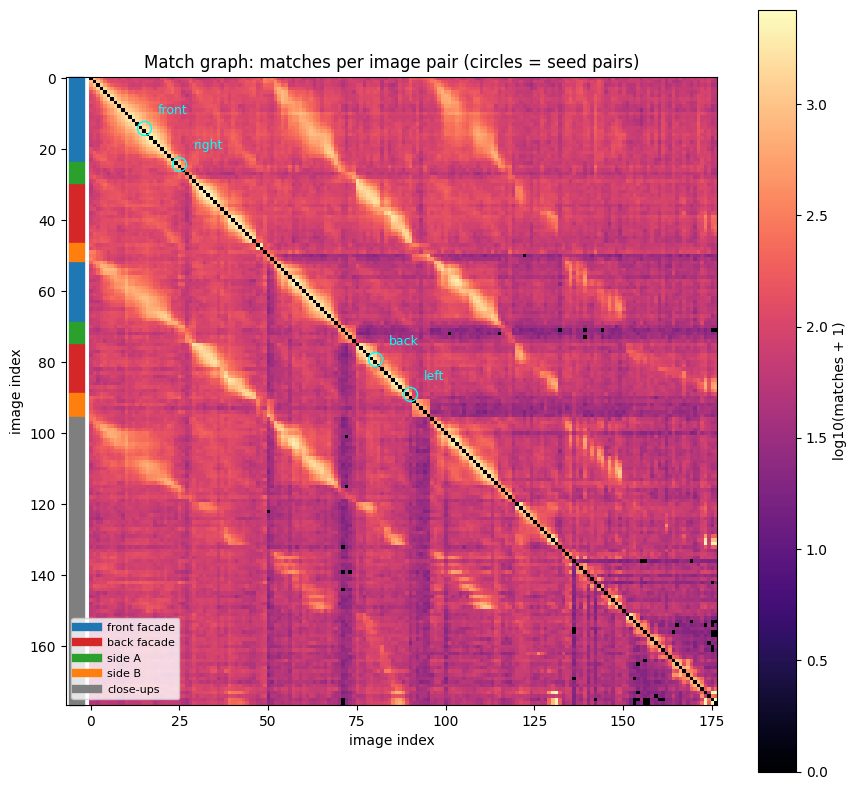

In [3]:
n_kp = np.array([len(v) for v in kp_xy.values()])
mc = run["match_counts"]; pairs = mc[np.triu_indices_from(mc, 1)]
print(f"keypoints per image: median {np.median(n_kp):.0f} (min {n_kp.min()}, max {n_kp.max()})")
print(f"image pairs with >= 15 matches: {(pairs >= 15).sum()} of {len(pairs)} ({np.mean(pairs >= 15):.1%})")
fb = mc[np.ix_(groups["front facade"], groups["back facade"])]
print(f"front <-> back photo pairs with >= 15 matches: {np.mean(fb >= 15):.0%} (median {np.median(fb):.0f} matches)")
plot_match_matrix(mc, groups, seeds)

## 2. Seed pairs

A sub-model starts from two views: $E = [t]_\times R$ from the 5-point algorithm, the correct one of the
four $(R, t)$ candidates by cheirality, then triangulation. A seed can fail in two ways, and each number tests one:
- **Median triangulation angle (parallax)**: the angle between the two viewing rays of a point. Too small and the rays are
  nearly parallel, so depth is badly constrained ($\sigma_z \approx z^2\sigma_{px}/(f\,b)$). Rule of thumb: ≳ 4°.
- **H/E ratio**: inliers of a homography $H$ divided by inliers of $E$. $H$ only describes two special cases: all points on
  **one plane**, or a camera that **only rotates**. If $H$ explains the matches as well as $E$ (H/E ≳ 0.8–1), the scene is
  effectively one of these cases and $E$, hence the pose, is ill-conditioned (the planar degenerate case).

A seed also needs **many points**: every later PnP registration is a 2D-3D match against them, and with few matches
$E$ and the angle themselves are unreliable. Below: the seeds used, then per part of the building the neighbouring pairs
that are valid seeds (**≥ 500 points, angle ≥ 4°, H/E < 0.8**, both images showing that part), ranked by points.

The translation has unit length, so each sub-model's unit is its seed baseline (scale ambiguity).

In [4]:
pm = run["pair_matches"]
pair_scores = {p: score_seed_pair(kp_xy[p[0]], kp_xy[p[1]], m, K) for p, m in pm.items() if len(m) >= 30}
rows = []
for name, (a, b) in seeds.items():
    s = pair_scores.get(tuple(sorted((a, b))))
    rows.append({"sub-model": name, "seed": f"({a}, {b})", **(s or {})})
print_table(rows, [("sub-model", "sub-model"), ("seed", "seed pair"), ("matches", "matches"),
                   ("e_inliers", "E inliers"), ("points", "3D points"), ("angle", "median angle [deg]"),
                   ("h_ratio", "H/E")],
            {"angle": "{:.1f}", "h_ratio": "{:.2f}"})
rank_seed_candidates(pair_scores, groups, seeds, min_points=500, min_angle_deg=4.0, max_h_ratio=0.8)

sub-model  seed pair  matches  E inliers  3D points  median angle [deg]   H/E
---------  ---------  -------  ---------  ---------  ------------------  ----
    front   (14, 15)     1723       1424       1424                 6.9  0.59
     back   (79, 80)     1858       1182       1182                 8.5  0.69
     left   (89, 90)      907        544        544                11.4  0.69
    right   (24, 25)     1135        750        750                10.0  0.78

front facade: 32 valid of 39 neighbour pairs
rank      pair  3D points  median angle [deg]   H/E                 
----  --------  ---------  ------------------  ----  ---------------
   1  (57, 58)       2139                 7.4  0.60                 
   2  (17, 18)       1760                 5.2  0.58                 
   3  (15, 16)       1696                 6.6  0.57                 
   4  (16, 17)       1560                 7.3  0.67                 
   5  (18, 19)       1493                 7.9  0.55                 
   

**Choosing among valid candidates: trial runs.** The two-view numbers only say whether a seed *can* work, not which one
gives the best reconstruction. On the sides the seeds used are the only valid candidates (side B) or the best one (side A).
For front and back, pairs with more points exist, so they were tested with the full pipeline
(registration, merge, global BA; PnP min. 30 inliers; separate experiment, not recomputed here):

| front / back seed | cameras | points with ≥ 3 views | RMSE after BA [px] | back merge: camera error max | back facade |
|---|---|---|---|---|---|
| **(14, 15) / (79, 80), used** | 132 | **24 309** | 1.068 | 1.53 | correct |
| (57, 58) / (79, 80) | 130 | 24 112 | 1.081 | 5.51 | correct |
| (14, 15) / (85, 86) | **133** | 21 465 | 1.065 | 1.65 | correct |
| (57, 58) / (85, 86) | 131 | 21 270 | 1.081 | 5.81 | correct |
| (14, 15) / (32, 33) | 132 | 23 113 | **1.060** | **0.62** | correct |

- **More seed points do not mean a better result**: front (57, 58) has 50 % more seed points but gives fewer cameras,
  fewer well-constrained points and a higher RMSE. The seed only shapes the start, later the PnP chain dominates.
- Back (32, 33) merges more cleanly but keeps 5 % fewer multi-view points: a draw, no reason to switch.
- **Every combination reconstructs the building correctly**, so the result does not hinge on the exact seed choice.

(Camera errors are in units of the front seed baseline, so values for front (57, 58) are only roughly comparable;
cameras, points and RMSE do not depend on that unit.)

## 3. Sub-models: incremental registration

Each sub-model registers images by **PnP + RANSAC** against its 3D points, triangulates new points and runs a
sliding-window local BA. All guardrails are **scale free** (pixels, angles, signs, ratios to medians),
because each sub-model has its own arbitrary unit. The left and right models never see the back-facade photos:
otherwise symmetric front/back matches give them mirrored poses (folding the back onto the front).

sub-model      seed  cameras  3D points  observations  track len median  mean  >= 3 views
---------  --------  -------  ---------  ------------  ----------------  ----  ----------
    front  (14, 15)       66      43080        123881                 2  2.88         30%
     back  (79, 80)       43      34302         95845                 2  2.79         33%
     left  (89, 90)       76      47042        136994                 2  2.91         33%
    right  (24, 25)       48      22961         62272                 2  2.71         26%


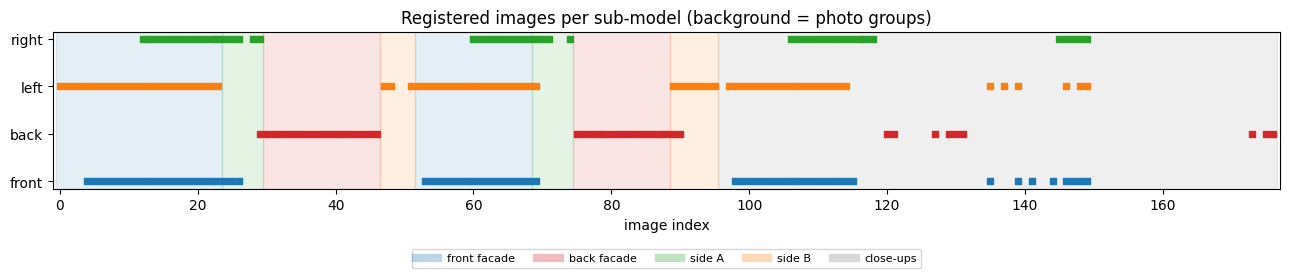

In [5]:
rows = []
for name, sm in run["submodels"].items():
    tl = track_lengths(sm["track"], sm["cameras"])
    rows.append({"name": name, "seed": str(seeds[name]), "cams": len(sm["cameras"]), "pts": len(sm["track"]["points"]),
                 "obs": len(sm["track"]["obs"]), "tl_med": np.median(tl), "tl_mean": tl.mean(), "tl3": np.mean(tl >= 3)})
print_table(rows, [("name", "sub-model"), ("seed", "seed"), ("cams", "cameras"), ("pts", "3D points"),
                   ("obs", "observations"), ("tl_med", "track len median"), ("tl_mean", "mean"), ("tl3", ">= 3 views")],
            {"tl_med": "{:.0f}", "tl_mean": "{:.2f}", "tl3": "{:.0%}"})
plot_submodel_coverage(run["submodels"], run["n_images"], groups)

## 4. Merging the sub-models: Sim(3) with RANSAC + Umeyama

Sub-models are aligned into the front frame with $X_{front} = s R X_{sub} + t$, solved in closed form by
Umeyama (SVD of the cross-covariance, with the $\det = +1$ correction) on 3D points both models share
through identical keypoint observations; RANSAC over minimal 3-point samples removes wrong correspondences.

**Check:** images registered in both models are the same physical camera, so their centers must coincide
after the alignment (*camera error*, in units of the front seed baseline).

#  merged  cams  new cams  shared cams  shared pts  Umeyama inliers  cam err median  cam err max  scale s  new pts  fused pts
-  ------  ----  --------  -----------  ----------  ---------------  --------------  -----------  -------  -------  ---------
1    left    76        17           59       36872              49%           0.178         3.06    0.869    10170      36872
2   right    48         9           39       20272              11%           0.627         2.41    0.908     2689      20272
3    back    43        40            3        1124              48%           0.155         1.53    0.704    33178       1124

points in all sub-models: 147385 -> merged model: 89117 (58268 fused) | cameras: 132 / 177


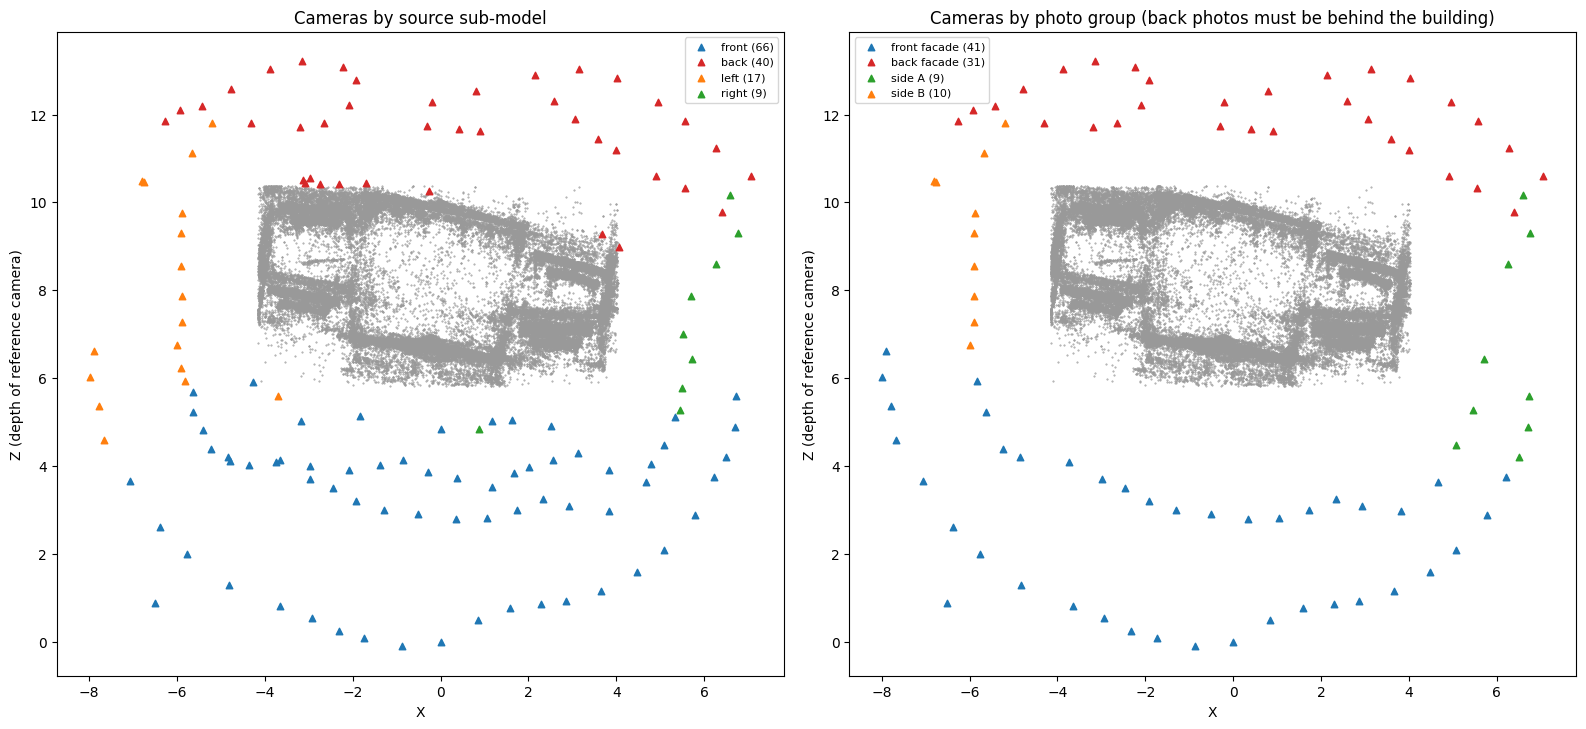

In [6]:
rows = [{"step": i + 1, **s, "inl": s.get("inliers", 0) / max(s.get("candidates", 1), 1)} for i, s in enumerate(run["merge_stats"])]
print_table(rows, [("step", "#"), ("name", "merged"), ("cameras", "cams"), ("new_cameras", "new cams"),
                   ("shared_cameras", "shared cams"), ("shared_points", "shared pts"), ("inl", "Umeyama inliers"),
                   ("cam_err_median", "cam err median"), ("cam_err_max", "cam err max"), ("scale", "scale s"),
                   ("new_points", "new pts"), ("fused_points", "fused pts")],
            {"inl": "{:.0%}", "cam_err_median": "{:.3f}", "cam_err_max": "{:.2f}", "scale": "{:.3f}"})

sub_pts = sum(len(sm["track"]["points"]) for sm in run["submodels"].values())
bb = run["before_ba"]
print(f"\npoints in all sub-models: {sub_pts} -> merged model: {len(bb['track']['points'])} "
      f"({sub_pts - len(bb['track']['points'])} fused) | cameras: {len(bb['cameras'])} / {run['n_images']}")

ab = run["after_ba"]; pts = np.array(list(ab["track"]["points"].values()))
photo_group = {i: g for g, ids in groups.items() for i in ids}
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_cameras_topview(ab["cameras"], pts, run["cam_source"], SUBMODEL_COLORS, "Cameras by source sub-model", ax=axes[0])
plot_cameras_topview(ab["cameras"], pts, photo_group, {g: GROUP_COLORS[g] for g in ["front facade", "back facade", "side A", "side B"]},
                     "Cameras by photo group (back photos must be behind the building)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. Global bundle adjustment

Minimizes the reprojection error of all cameras and points jointly,
$\min \sum_{ij} \rho\left(\lVert x_{ij} - \pi(K(R_i X_j + T_i))\rVert\right)$ with a Huber loss $\rho$,
in two rounds (drop observations > 20 px → BA → drop > 4 px → BA). One camera is held fixed;
note this removes 6 of the 7 gauge freedoms of a monocular reconstruction, the scale stays free.

**How to read:** an *observation* is one 2D measurement, a keypoint in one image assigned to a 3D point, i.e. one viewing
ray from a camera to a point (a point with track length 3 has 3 observations). The histogram shows the reprojection error of
every observation; errors above 20 px are **clipped**, i.e. counted in the last bar at 20 instead of stretching the axis, so
that bar collects all gross outliers before BA, exactly what the first filter round removes.

                  state  cameras  3D points  observations  RMSE [px]  median err [px]  mean track len
-----------------------  -------  ---------  ------------  ---------  ---------------  --------------
after merge (before BA)      132      89117        265797      40.61             1.45            2.98
        after global BA      132      75239        213960       1.07             0.96            2.84
RMSE per image coordinate (same convention as the BA log); before BA it includes the gross outliers
that the BA filter rounds remove, the median shows the typical error.


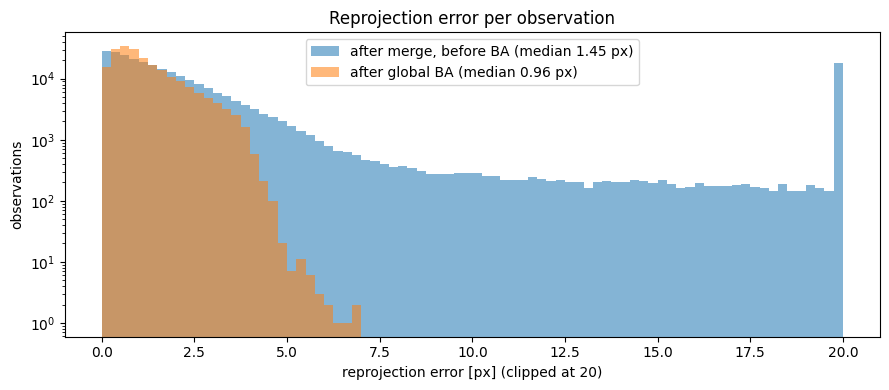

In [7]:
tri = Triangulator(K)
err_b = tri.track_reprojection_errors(bb["cameras"], as_track_graph(bb["track"]), run["all_kp"])[1]
err_a = tri.track_reprojection_errors(ab["cameras"], as_track_graph(ab["track"]), run["all_kp"])[1]
tl_b, tl_a = track_lengths(bb["track"], bb["cameras"]), track_lengths(ab["track"], ab["cameras"])
rows = [{"state": "after merge (before BA)", "cams": len(bb["cameras"]), "pts": len(bb["track"]["points"]), "obs": len(err_b),
         "rmse": np.sqrt(np.mean(np.minimum(err_b, 1e6) ** 2) / 2), "med": np.median(err_b), "tl": tl_b.mean()},
        {"state": "after global BA", "cams": len(ab["cameras"]), "pts": len(ab["track"]["points"]), "obs": len(err_a),
         "rmse": np.sqrt(np.mean(err_a ** 2) / 2), "med": np.median(err_a), "tl": tl_a.mean()}]
print_table(rows, [("state", "state"), ("cams", "cameras"), ("pts", "3D points"), ("obs", "observations"),
                   ("rmse", "RMSE [px]"), ("med", "median err [px]"), ("tl", "mean track len")],
            {"rmse": "{:.2f}", "med": "{:.2f}", "tl": "{:.2f}"})
print("RMSE per image coordinate (same convention as the BA log); before BA it includes the gross outliers")
print("that the BA filter rounds remove, the median shows the typical error.")
plot_error_histograms(err_b, err_a)

## 6. Point quality and final point cloud

Points seen in only **two views** have no redundancy: an error along the epipolar line moves them in depth
undetected (this makes walls "thick" and ruins surface normals). A third view verifies the point, and more
views average the noise. The export keeps points with **≥ 3 views, ≥ 5° triangulation angle, ≤ 2 px error**;
that filter is why the final views below look much cleaner than the unfiltered clouds above (color = third coordinate).

**Why the tracks are short.** The median track length is 2 (about 70 % of the points are seen in only two views).
This reflects the capture rather than a pipeline error: consecutive photos differ by a large viewpoint change
(median parallax between neighbouring photos ≈ 10–11°), the stone surfaces have little texture, and the two loops were taken at
different distances, so SIFT re-detects and matches a feature in only a few images. A tested track-merging step
(fusing duplicate tracks, verified by multi-view DLT triangulation and reprojection error) increased the mean track
length by about 19 % but not the number of points with ≥ 3 views, so it was not added. Denser photos or dense
multi-view stereo would be the way to get longer tracks / more surface points.

Point quality filter (track >= 3, angle >= 5.0 deg, reproj <= 2.0 px): keeps 21957 / 75239 points (29%) | seen in only 2 views: 68%


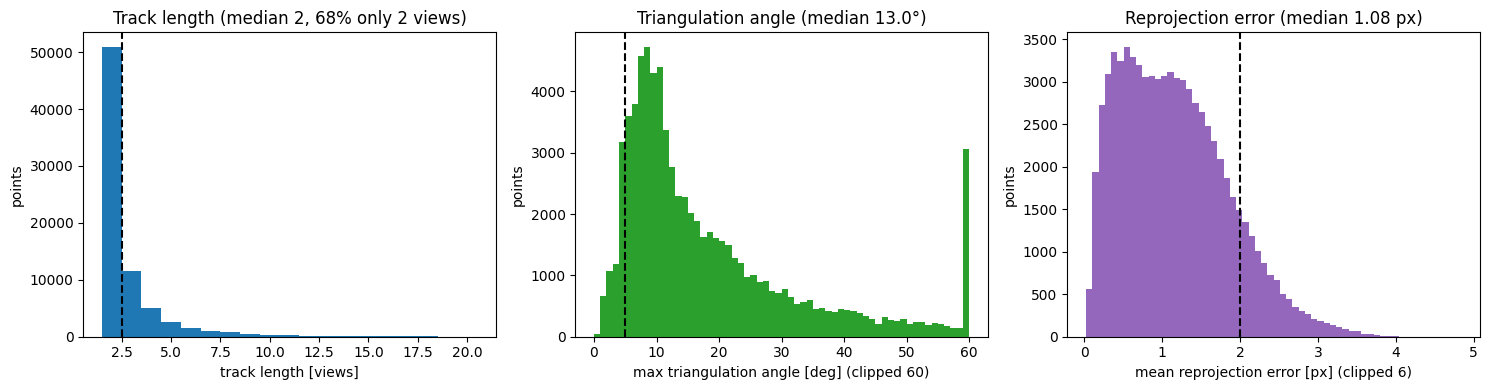

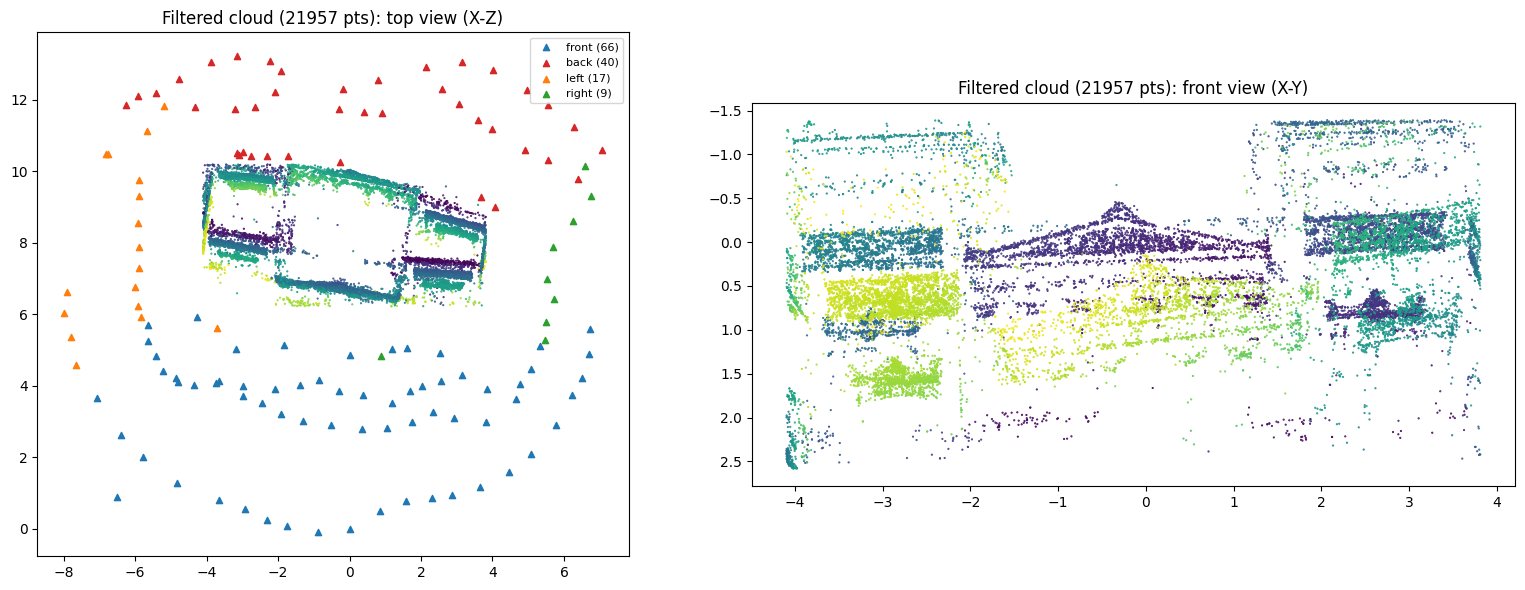

In [8]:
tg = as_track_graph(ab["track"])
quality = point_quality(tg, ab["cameras"], run["all_kp"], Triangulator(K))
good = point_quality_mask(quality, min_track_length=3, min_angle_deg=5.0, max_reproj_px=2.0)
plot_point_quality(quality)
final_pts = np.array(list(tg.global_points3D.values()))[good]
plot_cloud_views(final_pts, ab["cameras"], run["cam_source"], f"Filtered cloud ({len(final_pts)} pts)")

## 7. Summary

In [9]:
summary = [
    ("images", run["n_images"]),
    ("registered cameras", f"{len(ab['cameras'])} ({len(ab['cameras']) / run['n_images']:.0%})"),
    ("seed pairs", ", ".join(f"{n} {s}" for n, s in seeds.items())),
    ("sub-model points (sum) -> merged", f"{sub_pts} -> {len(bb['track']['points'])}"),
    ("3D points after global BA", len(ab["track"]["points"])),
    ("reprojection RMSE after BA", f"{np.sqrt(np.mean(err_a ** 2) / 2):.2f} px per coordinate"),
    ("median track length / >= 3 views", f"{np.median(tl_a):.0f} / {np.mean(tl_a >= 3):.0%}"),
    ("points kept by quality filter", f"{good.sum()} ({good.mean():.0%})"),
    ("max camera error in merges", f"{max(s.get('cam_err_max', 0) for s in run['merge_stats']):.2f} (front-seed units)"),
]
w = max(len(k) for k, _ in summary)
for k, v in summary:
    print(f"{k.ljust(w)} : {v}")

images                           : 177
registered cameras               : 132 (75%)
seed pairs                       : front (14, 15), back (79, 80), left (89, 90), right (24, 25)
sub-model points (sum) -> merged : 147385 -> 89117
3D points after global BA        : 75239
reprojection RMSE after BA       : 1.07 px per coordinate
median track length / >= 3 views : 2 / 32%
points kept by quality filter    : 21957 (29%)
max camera error in merges       : 3.06 (front-seed units)
